# 02 · Improving the Fraud Detection Model

**Notebook 01** follows the tutorial: exploratory data analysis + a Logistic Regression baseline.
That baseline catches 94% of frauds (recall) but its **precision on the fraud class is only 0.02** —
for every real fraud it raises ~44 false alarms (101,499 false positives on the test set).
A model like that would be unusable in a real bank: analysts would drown in alerts.

This notebook shows, step by step, how the model was improved:

| Step | What | Why |
|---|---|---|
| 1 | Load data with compact dtypes | 6.3M rows; cut memory from ~1.5 GB to ~0.3 GB |
| 2 | Domain analysis | Where does fraud happen? What does it look like in the balances? |
| 3 | Feature engineering | `errorBalanceOrig`, `errorBalanceDest`, `hour` |
| 4 | Train / validation / test split | Same test split as the tutorial → fair comparison |
| 5 | Reproduce the baseline | Same model as the tutorial, on the same test set |
| 6 | XGBoost pipeline | Non-linear model that can learn rules like "balance emptied *and* receiver unchanged" |
| 7 | Threshold tuning | Choose the cut-off on validation data, not the default 0.5 |
| 8 | Evaluation & comparison | Precision, recall, F1, PR-AUC, confusion matrices |
| 9 | Explainability | Which features drive the predictions? |
| 10 | Robustness check | Train on the past, test on the future (time-based split) |
| 11 | Overfitting check | Train vs. test scores + 5-fold cross-validation |
| 12 | Save the model | Used by the Streamlit app |

In [1]:
# Make the project root importable so we can reuse the shared code in src/features.py
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import warnings
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, PrecisionRecallDisplay, average_precision_score,
    classification_report, confusion_matrix, f1_score, precision_score, recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src.features import (
    INPUT_COLUMNS, MODEL_PATH, PROJECT_ROOT, TARGET,
    add_features, build_pipeline, load_data, threshold_for_recall,
)

sns.set(style="whitegrid")
IMG_DIR = PROJECT_ROOT / "images"
IMG_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42

## 1. Load the data

Only the columns that are used are loaded, and `type` is stored as a `category`.
`nameOrig` / `nameDest` are customer IDs (almost all unique → no generalizable signal) and
`isFlaggedFraud` is the output of the bank's existing rule system, so they are not model inputs.

In [2]:
df = load_data()
print(f"Rows: {len(df):,}")
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")
print(f"Fraud rate: {df[TARGET].mean():.4%}")
df.head()

Rows: 6,362,620
Memory: 0.32 GB
Fraud rate: 0.1291%


,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
0,1,PAYMENT,9839.64,170136.0,160296.36,0.0,0.0,0
1,1,PAYMENT,1864.28,21249.0,19384.72,0.0,0.0,0
2,1,TRANSFER,181.00,181.0,0.00,0.0,0.0,1
3,1,CASH_OUT,181.00,181.0,0.00,21182.0,0.0,1
4,1,PAYMENT,11668.14,41554.0,29885.86,0.0,0.0,0


## 2. Domain analysis — where does fraud happen?

The PaySim simulation models a fraudster who takes over an account, **transfers** the money to a
mule account and then **cashes it out**. So fraud should appear only in `TRANSFER` and `CASH_OUT`.

In [3]:
fraud_by_type = df.groupby("type", observed=True)[TARGET].agg(transactions="count", frauds="sum")
fraud_by_type["fraud_rate_%"] = (fraud_by_type["frauds"] / fraud_by_type["transactions"] * 100).round(3)
fraud_by_type.sort_values("frauds", ascending=False)

,transactions,frauds,fraud_rate_%
type,,,
CASH_OUT,2237500,4116,0.184
TRANSFER,532909,4097,0.769
CASH_IN,1399284,0,0.000
DEBIT,41432,0,0.000
PAYMENT,2151495,0,0.000


✅ **Confirmed:** 100% of frauds are `TRANSFER` or `CASH_OUT`. `PAYMENT`, `CASH_IN` and `DEBIT` never contain fraud.
A tree-based model learns this rule by itself; a linear model can only approximate it.

Next, look at the balances. In a consistent ledger the sender's new balance should be
`old balance − amount` and the receiver's should be `old balance + amount`. Let's see how often that holds.

In [4]:
tc = df[df["type"].isin(["TRANSFER", "CASH_OUT"])]
fraud, normal = tc[tc[TARGET] == 1], tc[tc[TARGET] == 0]

def share(mask):
    return f"{mask.mean():.1%}"

pd.DataFrame({
    "fraud": [
        share(fraud["newbalanceOrig"] == 0),
        share((fraud["oldbalanceDest"] == 0) & (fraud["newbalanceDest"] == 0)),
        share(fraud["amount"] == fraud["oldbalanceOrg"]),
    ],
    "legitimate": [
        share(normal["newbalanceOrig"] == 0),
        share((normal["oldbalanceDest"] == 0) & (normal["newbalanceDest"] == 0)),
        share(normal["amount"] == normal["oldbalanceOrg"]),
    ],
}, index=[
    "sender account emptied (newbalanceOrig == 0)",
    "receiver balance 0 before & after",
    "amount == sender's whole balance",
])

,fraud,legitimate
sender account emptied (newbalanceOrig == 0),98.1%,90.1%
receiver balance 0 before & after,49.6%,0.1%
amount == sender's whole balance,97.8%,0.0%


Fraudsters typically **drain the whole account**, and the receiving side often shows **no matching balance change**.
Instead of hoping the model discovers these arithmetic relations, we give them to it directly.

## 3. Feature engineering

Defined in [`src/features.py`](../src/features.py) → `add_features()` (shared by training and the app):

- **`errorBalanceOrig`** = `newbalanceOrig + amount − oldbalanceOrg` → 0 when the sender's books add up
- **`errorBalanceDest`** = `oldbalanceDest + amount − newbalanceDest` → 0 when the receiver's books add up
- **`hour`** = `step % 24` → hour of day (`step` = hours since simulation start; the tutorial dropped it)

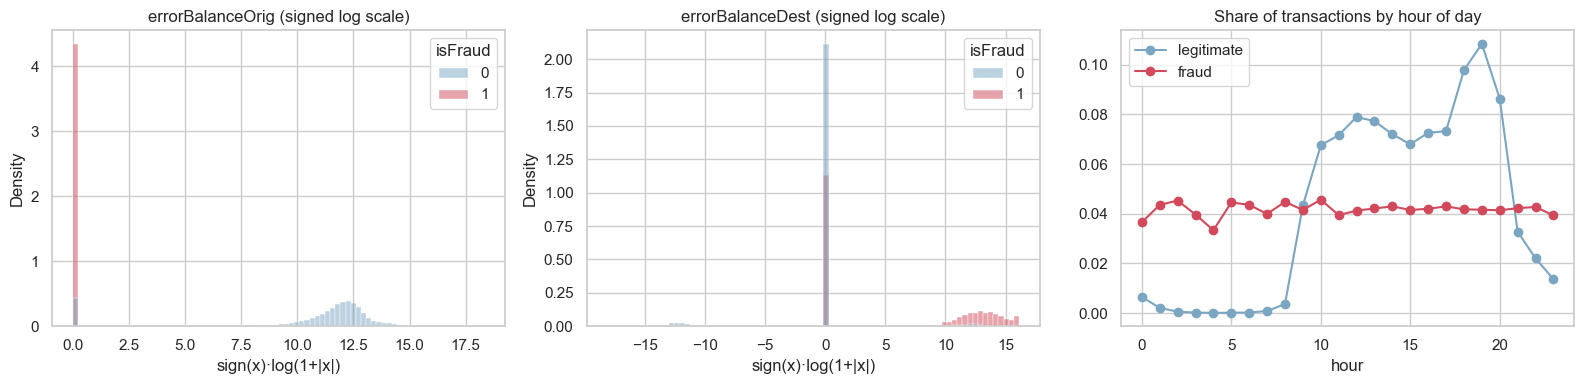

In [5]:
tc_feat = add_features(tc)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes[:2], ["errorBalanceOrig", "errorBalanceDest"]):
    # symmetric log so that both negative and positive errors are visible
    values = np.sign(tc_feat[col]) * np.log1p(np.abs(tc_feat[col]))
    sns.histplot(x=values, hue=tc_feat[TARGET], bins=80, stat="density",
                 common_norm=False, ax=ax, palette={0: "#7aa6c2", 1: "#d1495b"})
    ax.set_title(f"{col} (signed log scale)")
    ax.set_xlabel("sign(x)·log(1+|x|)")

hourly = tc_feat.groupby(["hour", TARGET]).size().unstack()
(hourly / hourly.sum()).plot(ax=axes[2], color=["#7aa6c2", "#d1495b"], marker="o")
axes[2].set_title("Share of transactions by hour of day")
axes[2].legend(["legitimate", "fraud"])
plt.tight_layout()
plt.savefig(IMG_DIR / "engineered_features.png", dpi=120, bbox_inches="tight")
plt.show()

- The balance-error distributions of fraud and legitimate transactions barely overlap → strong signal.
- Legitimate traffic nearly disappears between ~0:00 and 08:00 while fraud stays flat, so a transaction at
  4 AM is much more suspicious → `hour` adds signal the tutorial threw away.

## 4. Train / validation / test split

- **Test (30%)** — identical to the tutorial (`test_size=0.3, random_state=42, stratify=y`) so results are directly comparable.
- **Validation (15% of train)** — used *only* to pick the decision threshold. The test set is never used for any decision.

In [6]:
X, y = df[INPUT_COLUMNS], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.15, random_state=RANDOM_STATE, stratify=y_train)

for name, part in [("fit", y_fit), ("validation", y_val), ("test", y_test)]:
    print(f"{name:<11} {len(part):>9,} rows | frauds: {part.sum():>5,}")

fit         3,785,758 rows | frauds: 4,887
validation    668,076 rows | frauds:   862
test        1,908,786 rows | frauds: 2,464


## 5. Reproduce the tutorial baseline

Same pipeline as notebook 01 (StandardScaler + OneHotEncoder + `LogisticRegression(class_weight="balanced")`),
trained on the full 70% train split and evaluated on the same test set.

In [7]:
baseline = Pipeline([
    ("preprocessor", ColumnTransformer([
        ("num", StandardScaler(), ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]),
        ("cat", OneHotEncoder(drop="first"), ["type"]),
    ])),
    ("classifier", LogisticRegression(class_weight="balanced", random_state=RANDOM_STATE, max_iter=1000)),
])
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
baseline_proba = baseline.predict_proba(X_test)[:, 1]
print(classification_report(y_test, baseline_pred, digits=4))

              precision    recall  f1-score   support

           0     0.9999    0.9468    0.9726   1906322
           1     0.0223    0.9387    0.0435      2464

    accuracy                         0.9467   1908786
   macro avg     0.5111    0.9427    0.5081   1908786
weighted avg     0.9987    0.9467    0.9714   1908786



**Why is precision so low?** `class_weight="balanced"` makes each fraud ~770× more important than a normal
transaction, so the model pushes its decision boundary far into legitimate territory to avoid missing fraud.
A linear model also can't express interactions like *"TRANSFER **and** the account was emptied **and** the receiver
balance didn't change"*. The result: high recall, but ~100k false alarms.

## 6. Improved model: XGBoost pipeline

Defined in `src/features.py` → `build_pipeline()`:

```
raw columns ─► add_features() ─► OneHotEncoder(type) + numeric passthrough ─► XGBClassifier
```

- **Gradient-boosted trees** capture non-linear rules and feature interactions and need no scaling.
- `tree_method="hist"` keeps training on ~3.8M rows fast (well under a minute on a laptop).
- No class weighting or resampling (SMOTE etc.): with informative features the model separates the classes well,
  and the precision/recall trade-off is controlled explicitly with the threshold in the next step.
- Everything lives in a single sklearn `Pipeline`, so the saved model takes **raw** transaction columns.

In [8]:
%%time
model = build_pipeline(random_state=RANDOM_STATE)
model.fit(X_fit, y_fit)

CPU times: user 1min 13s, sys: 1.54 s, total: 1min 15s
Wall time: 14.3 s


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('features', ...), ('preprocessor', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...t 0x11982d120>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictionary of additional keyword arguments 

## 7. Threshold tuning

`predict()` uses a 0.5 probability cut-off, which is arbitrary. The business question is:
*"How many false alarms do we need to accept to catch X% of fraud?"*

**Rule used:** on the validation set, pick the **highest threshold that still catches ≥ 95% of frauds**
(the tutorial caught 94%). The higher the threshold, the fewer false alarms — so this gives the best
precision possible while catching *at least as much fraud as the baseline*.

In [9]:
val_proba = model.predict_proba(X_val)[:, 1]
threshold = threshold_for_recall(y_val, val_proba, min_recall=0.95)
print(f"Chosen threshold: {threshold:.3f}")

# How precision / recall move with the threshold (validation set)
rows = []
for t in [0.1, 0.2, 0.3, threshold, 0.5, 0.7, 0.9]:
    p = (val_proba >= t).astype(int)
    rows.append({"threshold": round(t, 3), "precision": precision_score(y_val, p),
                 "recall": recall_score(y_val, p), "f1": f1_score(y_val, p)})
pd.DataFrame(rows).round(4)

Chosen threshold: 0.416


,threshold,precision,recall,f1
0,0.100,0.8854,0.9861,0.9330
1,0.200,0.9114,0.9780,0.9435
2,0.300,0.9315,0.9629,0.9469
3,0.416,0.9457,0.9501,0.9479
4,0.500,0.9539,0.9362,0.9450
5,0.700,0.9728,0.9130,0.9420
6,0.900,0.9858,0.8828,0.9315


## 8. Evaluation on the test set & comparison with the tutorial

In [10]:
test_proba = model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= threshold).astype(int)
print(classification_report(y_test, test_pred, digits=4))

              precision    recall  f1-score   support

           0     0.9999    0.9999    0.9999   1906322
           1     0.9444    0.9509    0.9476      2464

    accuracy                         0.9999   1908786
   macro avg     0.9722    0.9754    0.9738   1908786
weighted avg     0.9999    0.9999    0.9999   1908786



In [11]:
def summarize(y_true, y_pred, y_proba):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "precision (fraud)": precision_score(y_true, y_pred),
        "recall (fraud)": recall_score(y_true, y_pred),
        "f1 (fraud)": f1_score(y_true, y_pred),
        "PR-AUC": average_precision_score(y_true, y_proba),
        "accuracy": (tp + tn) / len(y_true),
        "frauds caught": tp,
        "frauds missed": fn,
        "false alarms": fp,
    }

comparison = pd.DataFrame({
    "Tutorial (LogReg)": summarize(y_test, baseline_pred, baseline_proba),
    "Improved (XGBoost + features)": summarize(y_test, test_pred, test_proba),
}).T
comparison.style.format({c: "{:.4f}" for c in ["precision (fraud)", "recall (fraud)", "f1 (fraud)", "PR-AUC", "accuracy"]}
                        | {c: "{:,.0f}" for c in ["frauds caught", "frauds missed", "false alarms"]})

,precision (fraud),recall (fraud),f1 (fraud),PR-AUC,accuracy,frauds caught,frauds missed,false alarms
Tutorial (LogReg),0.0223,0.9387,0.0435,0.5452,0.9467,"2,313",151,"101,499"
Improved (XGBoost + features),0.9444,0.9509,0.9476,0.9867,0.9999,"2,343",121,138


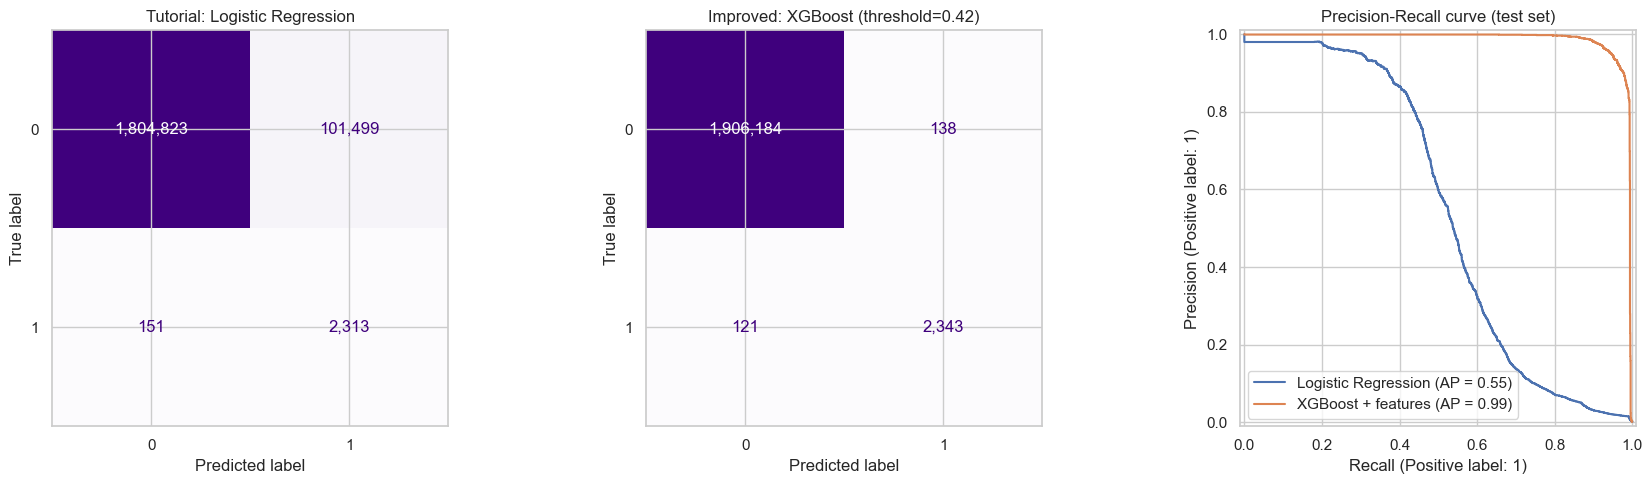

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ConfusionMatrixDisplay.from_predictions(y_test, baseline_pred, ax=axes[0], cmap="Purples",
                                        values_format=",", colorbar=False)
axes[0].set_title("Tutorial: Logistic Regression")
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, ax=axes[1], cmap="Purples",
                                        values_format=",", colorbar=False)
axes[1].set_title(f"Improved: XGBoost (threshold={threshold:.2f})")
PrecisionRecallDisplay.from_predictions(y_test, baseline_proba, ax=axes[2], name="Logistic Regression")
PrecisionRecallDisplay.from_predictions(y_test, test_proba, ax=axes[2], name="XGBoost + features")
axes[2].set_title("Precision-Recall curve (test set)")
plt.tight_layout()
plt.savefig(IMG_DIR / "model_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

**Accuracy is misleading here:** a model that predicts "not fraud" for everything already gets 99.87% accuracy.
That's why the project focuses on **precision, recall, F1 and PR-AUC of the fraud class**.

## 9. Explainability — which features matter?

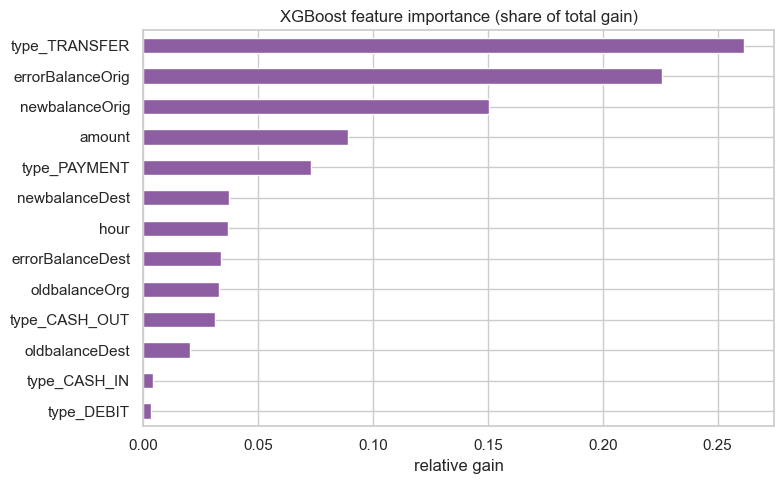

In [13]:
clf = model.named_steps["classifier"]
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
importance = (pd.Series(clf.get_booster().get_score(importance_type="gain"))
              .rename(index=lambda f: feature_names[int(f[1:])] if f.startswith("f") and f[1:].isdigit() else f)
              .sort_values())
importance = importance / importance.sum()

ax = importance.plot(kind="barh", figsize=(8, 5), color="#8e5ea2")
ax.set_title("XGBoost feature importance (share of total gain)")
ax.set_xlabel("relative gain")
plt.tight_layout()
plt.savefig(IMG_DIR / "feature_importance.png", dpi=120, bbox_inches="tight")
plt.show()

The transaction type and the engineered `errorBalanceOrig` feature dominate — i.e. the improvement comes mostly from
**understanding the domain**, not only from switching algorithms.

## 10. Robustness check — train on the past, predict the future

A random split mixes days, so the model can "see the future". In production a model is trained on historical data
and scores new transactions. Here we train on the first ~80% of the timeline (`step`) and test on the rest.

In [14]:
cutoff = df["step"].quantile(0.8)
past, future = df[df["step"] <= cutoff], df[df["step"] > cutoff]
print(f"train steps 1-{int(cutoff)} ({len(past):,} rows) | test steps {int(cutoff)+1}-{df['step'].max()} ({len(future):,} rows, {future[TARGET].sum()} frauds)")

time_model = build_pipeline(random_state=RANDOM_STATE).fit(past[INPUT_COLUMNS], past[TARGET])
future_pred = (time_model.predict_proba(future[INPUT_COLUMNS])[:, 1] >= threshold).astype(int)
print(classification_report(future[TARGET], future_pred, digits=4))

train steps 1-355 (5,113,884 rows) | test steps 356-743 (1,248,736 rows, 4250 frauds)


              precision    recall  f1-score   support

           0     0.9998    1.0000    0.9999   1244486
           1     0.9850    0.9409    0.9625      4250

    accuracy                         0.9998   1248736
   macro avg     0.9924    0.9704    0.9812   1248736
weighted avg     0.9997    0.9998    0.9997   1248736



The model keeps strong performance on future, unseen time steps. Note that the fraud share is much higher
in the late steps of the simulation (legitimate traffic drops while fraud continues), so these numbers are not
directly comparable with the random split — the point is that the model does not collapse on future data.

## 11. Overfitting check

Overfitting = the model memorizes the training data and performs much worse on data it has never seen.
Two checks:

1. **Train vs. validation vs. test** — compare the same metrics on data the model was trained on and on unseen data.
2. **5-fold cross-validation** — retrain the model on 5 different splits of the training data; stable scores mean
   the result does not depend on one lucky split.

In [15]:
def scores(X_part, y_part):
    proba = model.predict_proba(X_part)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {"precision": precision_score(y_part, pred), "recall": recall_score(y_part, pred),
            "f1": f1_score(y_part, pred), "PR-AUC": average_precision_score(y_part, proba)}

pd.DataFrame({
    "train": scores(X_fit, y_fit),
    "validation": scores(X_val, y_val),
    "test": scores(X_test, y_test),
}).T.round(4)

,precision,recall,f1,PR-AUC
train,0.9819,0.9892,0.9855,0.9984
validation,0.9457,0.9501,0.9479,0.9841
test,0.9444,0.9509,0.9476,0.9867


In [16]:
%%time
from sklearn.model_selection import StratifiedKFold

cv_rows = []
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for fold, (fit_idx, hold_idx) in enumerate(folds.split(X_train, y_train), start=1):
    fold_model = build_pipeline(random_state=RANDOM_STATE).fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
    pred = (fold_model.predict_proba(X_train.iloc[hold_idx])[:, 1] >= threshold).astype(int)
    y_hold = y_train.iloc[hold_idx]
    cv_rows.append({"fold": fold, "precision": precision_score(y_hold, pred),
                    "recall": recall_score(y_hold, pred), "f1": f1_score(y_hold, pred)})

cv = pd.DataFrame(cv_rows).set_index("fold")
print(f"F1 = {cv['f1'].mean():.4f} ± {cv['f1'].std():.4f}")
cv.round(4)

F1 = 0.9498 ± 0.0042
CPU times: user 6min 46s, sys: 10.4 s, total: 6min 57s
Wall time: 1min 25s


,precision,recall,f1
fold,,,
1,0.9447,0.9504,0.9476
2,0.9491,0.9400,0.9445
3,0.9569,0.9452,0.9510
4,0.9549,0.9565,0.9557
5,0.9449,0.9556,0.9502


**Conclusion — no harmful overfitting:**

- Training scores are a few points higher than validation/test scores. A small gap like this is normal for
  gradient-boosted trees; overfitting would look like a large drop (e.g. 0.99 on train → 0.70 on test).
- Validation and test scores are almost identical → the model generalizes to data it has never seen.
- Cross-validation scores are very stable across the 5 folds (small standard deviation).
- The time-based check in section 10 also shows strong performance on future data.

⚠️ The very high scores are mainly explained by the **synthetic nature of PaySim** (balances follow simple rules),
not by overfitting. On real banking data the scores would be lower.

## 12. Save the model

The pipeline and its threshold are saved together, so the Streamlit app uses exactly the same cut-off.
(The same model can be reproduced from the command line with `python -m src.train`.)

In [17]:
MODEL_PATH.parent.mkdir(exist_ok=True)
joblib.dump({"pipeline": model, "threshold": threshold}, MODEL_PATH)
print(f"Saved to {MODEL_PATH.relative_to(PROJECT_ROOT)} ({MODEL_PATH.stat().st_size / 1e6:.1f} MB)")

Saved to models/fraud_detection_pipeline.pkl (0.8 MB)


## Summary

| | Tutorial | This project |
|---|---|---|
| Model | Logistic Regression (balanced) | XGBoost in an sklearn Pipeline |
| Features | 5 raw numeric + type | + `errorBalanceOrig`, `errorBalanceDest`, `hour` |
| Decision threshold | default 0.5 | tuned on a validation set (≥95% recall) |
| Fraud precision | 0.02 | **~0.94** |
| Fraud recall | 0.94 | **~0.95** |
| False alarms on test set | ~101k | **~140** |